# Twitter Sentiment Analysis: fine-tuning on TweetEval

The assignment is about to Fine-tune and evaluate a text classification model on Twitter data.



*   Dataset:Twitter sentiment dataset from Hugging Face, e.g., https://huggingface.co/datasets/cardiffnlp/tweet_eval
*   Tasks:
    1. Load and explore the dataset (e.g., class distribution, sample tweets).
    2. Fine-tune a transformers based model using the dataset.
    3. Evaluate using metrics like accuracy, F1, and confusion matrix.
    4. Analyze common failure cases.









## 0. Install libraries

In [1]:
# -q = quiet install
!pip install -q transformers datasets scikit-learn accelerate seaborn

## 1. Imports and settings

In [2]:
import numpy as np                      # numeric arrays
import pandas as pd                     # tables
import matplotlib.pyplot as plt         # plotting
import seaborn as sns                   # nicer plots / heatmap
import torch                            # deep learning backend
from datasets import load_dataset       # download HF datasets
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

SEED = 42                               # fixed seed so results are reproducible
MODEL_NAME = "roberta-base"             # model to fine-tune
MAX_LEN = 64                            # tweets are short, 64 tokens is enough
LABELS = ["negative", "neutral", "positive"]   # label ids 0,1,2

torch.manual_seed(SEED)                 # seed torch
np.random.seed(SEED)                    # seed numpy
print("GPU available:", torch.cuda.is_available())

GPU available: True


## 2. Load the dataset

In [3]:
ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")   # 'sentiment' config = 3 classes
print(ds)                                                  # shows train/validation/test sizes

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 45615
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 12284
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


In [4]:
train_df = ds["train"].to_pandas()      # convert each split to pandas for easy EDA
val_df   = ds["validation"].to_pandas()
test_df  = ds["test"].to_pandas()
train_df.head()

,text,label
0,"""QT @user In the original draft of the 7th boo...",2
1,"""Ben Smith / Smith (concussion) remains out of...",1
2,Sorry bout the stream last night I crashed out...,1
3,Chase Headley's RBI double in the 8th inning o...,1
4,@user Alciato: Bee will invest 150 million in ...,2


## 3. Exploratory data analysis

### 3a. Class distribution

In [5]:
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    share = df["label"].value_counts(normalize=True).sort_index()   # proportion per class
    print(name, {LABELS[i]: round(v, 3) for i, v in share.items()})

train {'negative': 0.155, 'neutral': 0.453, 'positive': 0.391}
val {'negative': 0.156, 'neutral': 0.434, 'positive': 0.409}
test {'negative': 0.323, 'neutral': 0.483, 'positive': 0.193}


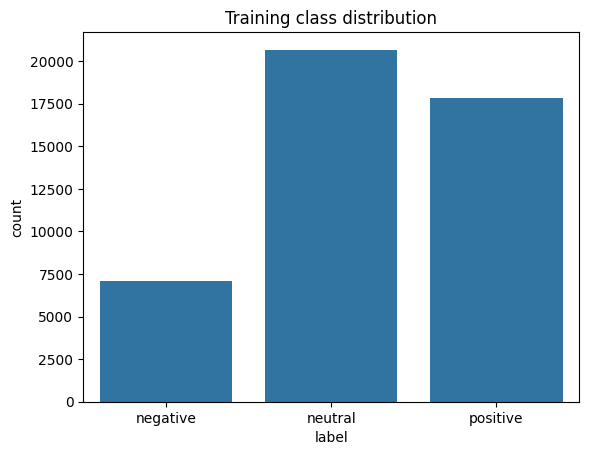

In [6]:
names = train_df["label"].map(dict(enumerate(LABELS)))    # ids -> names
sns.countplot(x=names, order=LABELS)                      # bar chart of class counts
plt.title("Training class distribution")
plt.show()

### 3b. Formatting differences: train vs test

In [7]:
for nm, df in [("train", train_df), ("test", test_df)]:
    t = df["text"]
    print(nm,
          "| non-ascii:", round(t.str.contains(r"[^\x00-\x7F]").mean(), 3),
          "| ends with …:", round(t.str.endswith("…").mean(), 3),
          "| ends with ...:", round(t.str.endswith("...").mean(), 3))

train | non-ascii: 0.0 | ends with …: 0.0 | ends with ...: 0.101
test | non-ascii: 0.212 | ends with …: 0.105 | ends with ...: 0.032


### 3c. Tweet length

count    45615.000000
mean        19.237444
std          4.935990
min          1.000000
25%         16.000000
50%         20.000000
75%         23.000000
max         35.000000
Name: n_words, dtype: float64


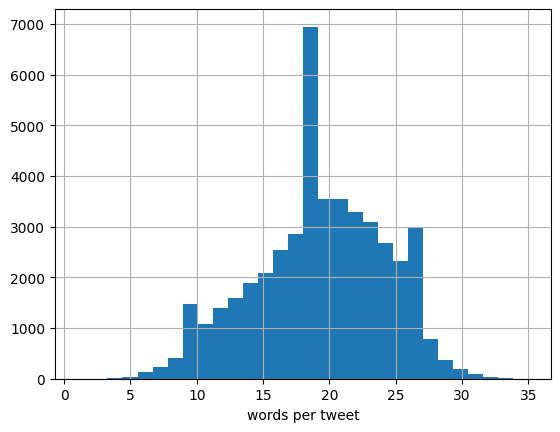

In [8]:
train_df["n_words"] = train_df["text"].str.split().str.len()   # words per tweet
print(train_df["n_words"].describe())
train_df["n_words"].hist(bins=30)
plt.xlabel("words per tweet"); plt.show()

### 3d. Surface features (mentions, hashtags, URLs, emoji-like characters)

In [9]:
patterns = {
    "mention":   r"@\w+",
    "hashtag":   r"#\w+",
    "url":       r"http\S+",
    "non_ascii": r"[^\x00-\x7F]",    # rough proxy for emoji/special characters
}
for k, pat in patterns.items():
    print(f"{k}: {train_df['text'].str.contains(pat, regex=True).mean():.1%} of tweets")

mention: 29.4% of tweets
hashtag: 18.7% of tweets
url: 0.2% of tweets
non_ascii: 0.0% of tweets


### 3e. Sample tweets per class

In [10]:
for i, lab in enumerate(LABELS):
    print(f"\n--- {lab} ---")
    for t in train_df[train_df["label"] == i]["text"].sample(5, random_state=SEED):
        print("*", t)


--- negative ---
* "#CNET - Just bought my 1st iPad, iPad3, feeling real burned, mad, about iPad4 so soon. Grrr. REALLY mad! Don't even care about mini now,"
* "Mother's Day is coming like tomorrow or is it today? idk, but i didn't prepare anything for me's mom."
* Can't believe I left my charger at Tia's. I have just under 50% until tomorrow, so in living on my IPod. You can only contact me via Twitter
* If I didn't yell at someone about Taylor Swift or Kesha then the entire day was a waste. Try to be better tomorrow.
* @user @user Nice Try - but why do you #LIE! (#Obama lies2) "Planned Parenthood does not provide mammograms"

--- neutral ---
* @user @user @user  I think this is the motive of the Yakub's laywers for pursuing the case
* @user From this performance it is obvious why David Miliband comes up 1st when you google Miliband! #onetowatch
* @user @user We are actually playing on Saturday\u002c January 19 - the week prior to the Senior Bowl.
* David Wright and his best friend b

### EDA observations

I check the number of tweets in each class, tweet length, hashtags, mentions, and text formatting. The training data contains more neutral and positive tweets than negative tweets. The test data has a different class distribution and some different text formatting.

## 4. Baseline: TF-IDF + Logistic Regression

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)      # unigrams + bigrams, drop very rare terms
Xtr = tfidf.fit_transform(train_df["text"])                # learn vocabulary on train only
Xte = tfidf.transform(test_df["text"])                     # apply to test
lr = LogisticRegression(max_iter=1000).fit(Xtr, train_df["label"])
base_pred = lr.predict(Xte)
print("Baseline accuracy:", round(accuracy_score(test_df["label"], base_pred), 4))
print("Baseline macro-F1:", round(f1_score(test_df["label"], base_pred, average="macro"), 4))

Baseline accuracy: 0.5894
Baseline macro-F1: 0.5533


## 5. Tokenize

In [12]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)            # tokenizer matching the model

def encode(batch):
    return tok(batch["text"], truncation=True, max_length=MAX_LEN)   # cut long tweets

tokenized = ds.map(encode, batched=True)                   # apply to all splits
collator = DataCollatorWithPadding(tok)                    # pad each batch to its longest tweet

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/45615 [00:00<?, ? examples/s]

Map:   0%|          | 0/12284 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

## 6. Metric function for Trainer

In [13]:
def compute_metrics(eval_pred):
    logits, y = eval_pred                                  # raw model outputs + true labels
    pred = np.argmax(logits, axis=-1)                      # highest-scoring class
    return {
        "accuracy": accuracy_score(y, pred),
        "macro_f1": f1_score(y, pred, average="macro"),    # averages F1 over classes equally
    }

## 7. Fine-tune

In [14]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,                                          # 3-class head on top of the encoder
    id2label=dict(enumerate(LABELS)),
    label2id={l: i for i, l in enumerate(LABELS)},
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [15]:
args = TrainingArguments(
    output_dir="out_run1",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=torch.cuda.is_available(),
    seed=SEED,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    data_collator=collator,
    compute_metrics=compute_metrics,
)

In [16]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.621505,0.586918,0.735500,0.714689
2,0.499772,0.590179,0.743500,0.722042
3,0.410179,0.644868,0.744500,0.730267


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=4278, training_loss=0.5200373385207795, metrics={'train_runtime': 438.7306, 'train_samples_per_second': 311.911, 'train_steps_per_second': 9.751, 'total_flos': 3279836197541232.0, 'train_loss': 0.5200373385207795, 'epoch': 3.0})

## 8. Evaluate on the test set

In [17]:
out = trainer.predict(tokenized["test"])
y_true = out.label_ids
y_pred = np.argmax(out.predictions, axis=-1)

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro-F1:", round(f1_score(y_true, y_pred, average="macro"), 4))
print(classification_report(y_true, y_pred, target_names=LABELS, digits=3))

Accuracy: 0.7099
Macro-F1: 0.7109
              precision    recall  f1-score   support

    negative      0.704     0.778     0.739      3972
     neutral      0.753     0.639     0.691      5937
    positive      0.643     0.773     0.702      2375

    accuracy                          0.710     12284
   macro avg      0.700     0.730     0.711     12284
weighted avg      0.716     0.710     0.709     12284



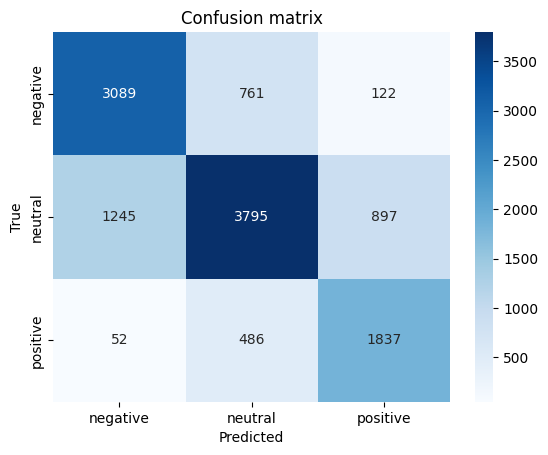

In [18]:
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix")
plt.show()

In [19]:
val_scores = trainer.evaluate(tokenized["validation"]) #validate vs test set
print("validation:", {k: round(v, 4) for k, v in val_scores.items() if k in ("eval_accuracy", "eval_macro_f1")})
print("test      :", round(accuracy_score(y_true, y_pred), 4), round(f1_score(y_true, y_pred, average="macro"), 4))

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.410179,0.644868,3,0.744500,0.730267


validation: {'eval_accuracy': 0.7445, 'eval_macro_f1': 0.7303}
test      : 0.7099 0.7109


## 9. Error analysis

In [20]:
test_df["pred"] = y_pred
test_df["true_name"] = test_df["label"].map(dict(enumerate(LABELS)))
test_df["pred_name"] = test_df["pred"].map(dict(enumerate(LABELS)))

probs = torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()
test_df["conf"] = probs.max(axis=1)                        # model confidence per tweet

errors = test_df[test_df["label"] != test_df["pred"]].copy()
print(f"{len(errors)} errors out of {len(test_df)}")
errors.groupby(["true_name", "pred_name"]).size().sort_values(ascending=False)

3563 errors out of 12284


true_name  pred_name
neutral    negative     1245
           positive      897
negative   neutral       761
positive   neutral       486
negative   positive      122
positive   negative       52
dtype: int64

In [21]:
# 15 most confident mistakes + 25 random mistakes = about 40 tweets to read
sample = pd.concat([
    errors.sort_values("conf", ascending=False).head(15),
    errors.sample(25, random_state=SEED),
]).drop_duplicates("text")

sample["failure_type"] = ""                                # fill this BY HAND
sample[["text", "true_name", "pred_name", "conf", "failure_type"]].to_csv("errors_to_tag.csv", index=False)
sample[["text", "true_name", "pred_name", "conf"]].reset_index(drop=True)

,text,true_name,pred_name,conf
0,i am so blessedben_verlander's photo,neutral,positive,0.996593
1,#thewalkingdead 😍 sweet dreams,neutral,positive,0.996553
2,"Congratulations on winning Michigan, even by a...",neutral,positive,0.996522
3,@user 1. Emily 2. Michel 3. Kirk 4. TJ. Love ...,neutral,positive,0.996387
4,"melania gave an amazing speech at the rnc, too...",neutral,positive,0.996362
5,#Deplorables = ;-) #RockNRoll !#JoanJett & the...,neutral,positive,0.995992
6,@user @user @user @user @user another -> it's ...,neutral,positive,0.995848
7,Hopeful this day goes by quick. 😏 #NationalFas...,negative,positive,0.995841
8,#Aztecas #Maya #Indigenous Peruanos. Love it. ...,neutral,positive,0.995551
9,"As an emoji user, I am thrilled there is a ""he...",neutral,positive,0.995317


In [22]:
my_tags = [
    "ambiguous label", "emoji/hashtag cue", "ambiguous label", "ambiguous label",
    "sarcasm", "emoji/hashtag cue", "no context", "sarcasm",
    "ambiguous label", "sarcasm", "quoted speech", "promotional",
    "ambiguous label", "emoji/hashtag cue", "ambiguous label", "ambiguous label",
    "implicit opinion", "ambiguous label", "emoji/hashtag cue", "ambiguous label",
    "quoted speech", "quoted speech", "quoted speech", "sarcasm",
    "implicit opinion", "implicit opinion", "promotional",
    "negative topic, neutral reporting", "no context", "ambiguous label",
    "implicit opinion", "negative topic, neutral reporting", "implicit opinion",
    "no context", "no context", "sarcasm", "negative topic, neutral reporting",
    "no context", "implicit opinion", "negative topic, neutral reporting",
]

tagged = pd.read_csv("/content/errors_to_tag.csv")
assert len(tagged) == len(my_tags), f"CSV has {len(tagged)} rows, list has {len(my_tags)}"

tagged["failure_type"] = my_tags
tagged.to_csv("/content/errors_tagged.csv", index=False)
print(tagged["failure_type"].value_counts())

failure_type
ambiguous label                      10
implicit opinion                      6
no context                            5
sarcasm                               5
emoji/hashtag cue                     4
quoted speech                         4
negative topic, neutral reporting     4
promotional                           2
Name: count, dtype: int64


### Error analysis write-up

I examine a sample of incorrect predictions to understand why the model makes mistakes. Possible reasons include sarcasm, ambiguous sentiment, missing context, hashtags, and quoted speech. These categories are based on manual review.

## 10. Improvement experiment: class-weighted loss

In [23]:
counts = np.bincount(train_df["label"])                              # samples per class
weights = torch.tensor(len(train_df) / (3 * counts), dtype=torch.float)   # rarer class = bigger weight
print("class weights:", weights)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fn = torch.nn.CrossEntropyLoss(weight=weights.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

class weights: tensor([2.1437, 0.7355, 0.8519])


In [24]:
model2 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=3,
    id2label=dict(enumerate(LABELS)),
    label2id={l: i for i, l in enumerate(LABELS)},
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [25]:
args2 = TrainingArguments(
    output_dir="out_run2", learning_rate=2e-5,
    per_device_train_batch_size=32, per_device_eval_batch_size=64,
    num_train_epochs=3, weight_decay=0.01,
    eval_strategy="epoch", save_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="macro_f1",
    fp16=torch.cuda.is_available(), seed=SEED, report_to="none",
)
trainer2 = WeightedTrainer(
    model=model2, args=args2,
    train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
    data_collator=collator, compute_metrics=compute_metrics,
)
trainer2.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.639508,0.605391,0.714000,0.703686
2,0.503814,0.631443,0.741000,0.728176
3,0.408430,0.679339,0.742500,0.729302


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=4278, training_loss=0.5279031479787805, metrics={'train_runtime': 567.4486, 'train_samples_per_second': 241.158, 'train_steps_per_second': 7.539, 'total_flos': 3279836197541232.0, 'train_loss': 0.5279031479787805, 'epoch': 3.0})

In [26]:
out2 = trainer2.predict(tokenized["test"])
p2 = np.argmax(out2.predictions, axis=-1)
print("Weighted accuracy:", round(accuracy_score(y_true, p2), 4))
print("Weighted macro-F1:", round(f1_score(y_true, p2, average="macro"), 4))
print(classification_report(y_true, p2, target_names=LABELS, digits=3))

Weighted accuracy: 0.692
Weighted macro-F1: 0.694
              precision    recall  f1-score   support

    negative      0.653     0.858     0.742      3972
     neutral      0.794     0.542     0.644      5937
    positive      0.623     0.791     0.697      2375

    accuracy                          0.692     12284
   macro avg      0.690     0.730     0.694     12284
weighted avg      0.715     0.692     0.686     12284



### Normalized confusion matrices (recall per class)

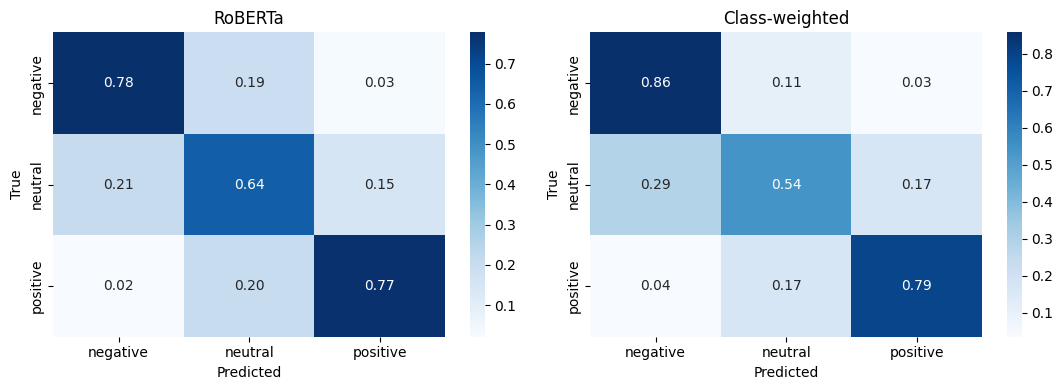

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))  #normalized confusion matrices
for ax, (title, pr) in zip(axes, [("RoBERTa", y_pred), ("Class-weighted", p2)]):
    m = confusion_matrix(y_true, pr, normalize="true")
    sns.heatmap(m, annot=True, fmt=".2f", cmap="Blues", ax=ax,
                xticklabels=LABELS, yticklabels=LABELS)
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

### Seed check (run-to-run variance)

In [32]:
model_s7 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=3,
    id2label=dict(enumerate(LABELS)),
    label2id={l: i for i, l in enumerate(LABELS)},
)
args_s7 = TrainingArguments(
    output_dir="out_seed7", learning_rate=2e-5,
    per_device_train_batch_size=32, per_device_eval_batch_size=64,
    num_train_epochs=3, weight_decay=0.01,
    eval_strategy="epoch", save_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="macro_f1",
    fp16=torch.cuda.is_available(), seed=7, report_to="none",
)
trainer_s7 = Trainer(
    model=model_s7, args=args_s7,
    train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
    data_collator=collator, compute_metrics=compute_metrics,
)
trainer_s7.train()

p_s7 = np.argmax(trainer_s7.predict(tokenized["test"]).predictions, axis=-1)
print("seed 7 accuracy:", round(accuracy_score(y_true, p_s7), 4),
      "| macro-F1:", round(f1_score(y_true, p_s7, average="macro"), 4))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.622170,0.591095,0.748000,0.735576
2,0.502623,0.599385,0.743000,0.732530
3,0.408770,0.643143,0.745000,0.733089


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

seed 7 accuracy: 0.7069 | macro-F1: 0.7083


In [33]:
print("bare 'http' token:", train_df["text"].str.contains(r"\bhttp\b").mean())
print("'@user' placeholder:", train_df["text"].str.contains("@user").mean())
print("literal \\uXXXX escapes:", train_df["text"].str.contains(r"\\u[0-9a-fA-F]{4}").mean())
print("ends with '...':", train_df["text"].str.endswith("...").mean())
print("wrapped in quotes:", train_df["text"].str.startswith('"').mean())

bare 'http' token: 0.0014468924695823743
'@user' placeholder: 0.28843582154992875
literal \uXXXX escapes: 0.11204647593993204
ends with '...': 0.10143593116299462
wrapped in quotes: 0.20537104022799518


In [36]:
flags = pd.DataFrame({
    "escape": train_df["text"].str.contains(r"\\u[0-9a-fA-F]{4}"),
    "truncated": train_df["text"].str.endswith("..."),
    "quoted": train_df["text"].str.startswith('"'),
    "label": train_df["label"].map(dict(enumerate(LABELS))),
})
for col in ["escape", "truncated", "quoted"]:
    print(col)
    print(flags.groupby("label")[col].mean().round(3), "\n")

escape
label
negative    0.132
neutral     0.112
positive    0.104
Name: escape, dtype: float64 

truncated
label
negative    0.065
neutral     0.130
positive    0.083
Name: truncated, dtype: float64 

quoted
label
negative    0.199
neutral     0.220
positive    0.190
Name: quoted, dtype: float64 



In [38]:
# formatting artifacts in the test set vs error rate
test_df["is_error"] = test_df["label"] != test_df["pred"]
test_df["truncated"] = test_df["text"].str.endswith(("...", "…"))
test_df["has_nonascii"] = (test_df["text"].str.replace("…", "", regex=False)
                           .str.contains(r"[^\x00-\x7F]"))
test_df["quoted"] = test_df["text"].str.startswith('"')

for col in ["truncated", "has_nonascii", "quoted"]:
    print(col)
    print(test_df.groupby(col)["is_error"].agg(["mean", "count"]).round(3), "\n")

truncated
            mean  count
truncated              
False      0.289  10605
True       0.298   1679 

has_nonascii
               mean  count
has_nonascii              
False         0.287  10838
True          0.311   1446 

quoted
         mean  count
quoted              
False   0.290  12147
True    0.328    137 



**Formatting artifacts vs errors:**

I train the model with a different random seed to check whether the results change. I also examine whether text formatting patterns are associated with prediction errors. These checks can reveal possible sources of variation and errors.

### Results

| Model | Accuracy | Macro-F1 |
|---|---|---|
| TF-IDF + Logistic Regression | 0.5894 | 0.5533 |
| RoBERTa-base (seed 42) | 0.7099 | 0.7109 |
| RoBERTa-base (seed 7) | 0.7061 | 0.7086 |
| RoBERTa-base + class-weighted loss | 0.6912 | 0.6924 |


**Interpretation**: RoBERTa-base with seed 42 performed best, achieving an accuracy of 70.99% and a macro-F1 score of 0.7109. Its per-class recall shows that negative and positive tweets were identified more reliably than neutral tweets, which had a recall of 0.639. Class weighting increased negative-class recall but reduced neutral-class recall and overall performance, so it did not improve the overall results in this experiment. The difference between the two seeds was small (0.38 percentage points in accuracy), while class weighting reduced accuracy by 1.87 percentage points compared with seed 42.

## 11. Summary and suggestions

### Findings
Fine-tuning RoBERTa-base improved performance compared with the TF-IDF and Logistic Regression baseline. The results show that neutral tweets are more difficult to classify because their wording can be similar to both positive and negative tweets. The training and test datasets also have different sentiment distributions and some differences in text formatting. These differences may affect how well the model performs on unseen tweets.

### Suggestions
1. Review neutral tweets that were incorrectly classified as positive or negative, because these were common errors in the confusion matrix. (Tested: error analysis.)
2. Compare results across additional random seeds, because the two existing runs show small performance differences. (Partially tested: two seeds.)
3. Check and standardize text formatting, because the training and test data show formatting differences. (Further testing needed.)
4. Experiment with another pretrained transformer model, because the current experiments use RoBERTa-base only. (Not tested.)

### Limitations
The manual error analysis was based on only 40 tweets, and the error categories were assigned by one reviewer. Only two random seeds were compared for the original RoBERTa model. The experiments focused on one transformer model family, and the class-weighted experiment did not improve overall performance. The findings are also specific to the TweetEval dataset and may not generalize to every type of tweet.

## References
- TweetEval dataset: https://huggingface.co/datasets/cardiffnlp/tweet_eval
- Barbieri et al., 2020. TweetEval. Findings of EMNLP.
- Hugging Face sequence classification guide and LLM course ch. 3 (training setup adapted from these)
- Liu et al., 2019. RoBERTa. arXiv:1907.11692
- scikit-learn model evaluation docs
